# Etapa 3 — Arquitectura de dos etapas (Candidate Generation + Ranking)

Inspirada en el enfoque de YouTube DNN (Covington et al., 2016). A diferencia de SVD y NCF, acá el problema se separa en dos fases con objetivos distintos:

- **Etapa A — Retrieval (Two-Tower):** un embedding por usuario y uno por ítem; el producto punto aproxima "qué tan bien le queda este ítem a este usuario". Se entrena con feedback implícito (positivo = rating ≥ 3.5) y negative sampling. Reduce el catálogo completo a un puñado de candidatos, de forma barata.
- **Etapa B — Ranker:** un modelo más expresivo que sólo puntúa los candidatos. A diferencia del retrieval, además de embeddings usa **características de contenido** (géneros del ítem, perfil de géneros del usuario, popularidad del ítem) y se entrena con **feedback implícito (BCE)**. En la versión anterior se entrenaba para predecir ratings, un objetivo que no se alinea con el de ordenar un top-N: empeoraba lo que el retrieval ya traía.

**Cómo se evalúa este modelo (por sí solo, sin forzar las métricas de las Etapas 1 y 2):** para cada usuario se genera un top-10 sobre el catálogo que no vio en train y se lo compara contra lo que efectivamente consumió y valoró bien en test (rating ≥ 3.5). Se miden precision, recall y NDCG, más dos métricas de sesgo (cobertura del catálogo y popularidad media de lo recomendado) y el tiempo por usuario. No se calcula RMSE/MAE: ya no hay un predictor de ratings.

**Contra qué se compara:** (1) un baseline de popularidad, (2) el retrieval solo, y (3) el ranker aplicado a *todo* el catálogo (una sola etapa). Esta última es la comparación clave: la arquitectura de dos etapas es útil si logra una calidad parecida a la de puntuar todo el catálogo con el modelo caro, pero puntuando sólo unos cientos de candidatos.

## 1. Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/tesis-recsys'
DATA_DIR = f'{PROJECT_DIR}/data'

Mounted at /content/drive


In [2]:
import torch
import random
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

Device: cuda


## 2. Carga de datos y split

Mismos índices, mismo `test_size` y `random_state` que en la Etapa 2, para que los tres modelos trabajen sobre el mismo escenario.

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

ratings = pd.read_csv(f'{DATA_DIR}/ml-latest-small/ratings.csv')

user_ids = ratings['userId'].unique()
item_ids = ratings['movieId'].unique()
user2idx = {u: i for i, u in enumerate(user_ids)}
item2idx = {m: i for i, m in enumerate(item_ids)}

ratings['user_idx'] = ratings['userId'].map(user2idx)
ratings['item_idx'] = ratings['movieId'].map(item2idx)

n_users = len(user2idx)
n_items = len(item2idx)

train_df, test_df = train_test_split(ratings, test_size=0.2, random_state=42)
print(f'Usuarios: {n_users}, Ítems: {n_items}')
print(f'Train: {len(train_df)} | Test: {len(test_df)}')

RATING_THRESHOLD = 3.5

Usuarios: 610, Ítems: 9724
Train: 80668 | Test: 20168


## 3. Etapa A — Retrieval (Two-Tower)

Armamos el conjunto de interacciones positivas de train (rating ≥ 3.5) y, para cada una, generamos negativos aleatorios (ítems que ese usuario no consumió en train). Es un negative sampling uniforme simple — más adelante, para el análisis de sesgo, va a ser interesante comparar contra negative sampling ponderado por popularidad.

In [4]:
# Ítems que cada usuario ya vio en train (para no samplear como negativo algo que sí interactuó)
user_seen_train = train_df.groupby('user_idx')['item_idx'].apply(set).to_dict()

train_positive = train_df[train_df['rating'] >= RATING_THRESHOLD]
print(f'Interacciones positivas en train: {len(train_positive)}')

all_item_idxs = np.arange(n_items)

def sample_negatives(user_idx_array, n_neg_per_pos=4):
    """Para cada usuario en user_idx_array, samplea n_neg_per_pos ítems que no vio en train."""
    neg_items = np.empty((len(user_idx_array), n_neg_per_pos), dtype=np.int64)
    for row, u in enumerate(user_idx_array):
        seen = user_seen_train.get(u, set())
        count = 0
        while count < n_neg_per_pos:
            candidate = np.random.randint(0, n_items)
            if candidate not in seen:
                neg_items[row, count] = candidate
                count += 1
    return neg_items

Interacciones positivas en train: 49377


In [5]:
from torch.utils.data import Dataset, DataLoader

N_NEG_PER_POS = 4

class RetrievalDataset(Dataset):
    """Cada muestra es (usuario, ítem_positivo, [ítems_negativos])."""
    def __init__(self, positive_df, n_neg_per_pos=N_NEG_PER_POS):
        self.users = positive_df['user_idx'].values
        self.pos_items = positive_df['item_idx'].values
        self.n_neg_per_pos = n_neg_per_pos
        # Los negativos se re-samplean una vez por construcción del dataset (por época, ver más abajo)
        self.neg_items = sample_negatives(self.users, n_neg_per_pos)

    def resample_negatives(self):
        self.neg_items = sample_negatives(self.users, self.n_neg_per_pos)

    def __len__(self):
        return len(self.users)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.users[idx], dtype=torch.long),
            torch.tensor(self.pos_items[idx], dtype=torch.long),
            torch.tensor(self.neg_items[idx], dtype=torch.long),
        )

BATCH_SIZE = 256
retrieval_dataset = RetrievalDataset(train_positive)
retrieval_loader = DataLoader(retrieval_dataset, batch_size=BATCH_SIZE, shuffle=True)

In [6]:
import torch.nn as nn

class TwoTower(nn.Module):
    def __init__(self, n_users, n_items, embed_dim=32):
        super().__init__()
        # Cada torre es, por ahora, un embedding simple. Es el punto exacto donde en la
        # Etapa 4 vamos a reemplazar la torre de ítems por algo que incorpore embeddings LLM.
        self.user_embedding = nn.Embedding(n_users, embed_dim)
        self.item_embedding = nn.Embedding(n_items, embed_dim)

        # Inicialización chica. Con la inicialización por defecto de nn.Embedding (normal estándar),
        # el producto punto de dos vectores de 32 dimensiones arranca con valores enormes (desvío ~6)
        # y el modelo pierde muchas épocas sólo en "desaprender" ese ruido inicial.
        nn.init.normal_(self.user_embedding.weight, mean=0.0, std=0.1)
        nn.init.normal_(self.item_embedding.weight, mean=0.0, std=0.1)

    def forward_user(self, user_idx):
        return self.user_embedding(user_idx)

    def forward_item(self, item_idx):
        return self.item_embedding(item_idx)

    def score(self, user_idx, item_idx):
        u = self.forward_user(user_idx)
        i = self.forward_item(item_idx)
        return (u * i).sum(dim=-1)

retrieval_model = TwoTower(n_users, n_items, embed_dim=32).to(device)
print(retrieval_model)

TwoTower(
  (user_embedding): Embedding(610, 32)
  (item_embedding): Embedding(9724, 32)
)


In [7]:
import torch.optim as optim

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(retrieval_model.parameters(), lr=5e-3, weight_decay=1e-6)

N_EPOCHS_RETRIEVAL = 30
retrieval_losses = []

# BCE de referencia: la de un modelo trivial que siempre predice la proporción base de positivos
# (1 positivo cada 1 + N_NEG_PER_POS muestras). Si el retrieval no baja de este valor, no aprendió nada útil.
p_pos = 1 / (1 + N_NEG_PER_POS)
trivial_bce = -(p_pos * np.log(p_pos) + (1 - p_pos) * np.log(1 - p_pos))
print(f'BCE de referencia (modelo trivial): {trivial_bce:.4f}')

for epoch in range(1, N_EPOCHS_RETRIEVAL + 1):
    retrieval_dataset.resample_negatives()  # negativos distintos cada época
    retrieval_model.train()
    epoch_loss = 0.0

    for users_batch, pos_items_batch, neg_items_batch in retrieval_loader:
        users_batch = users_batch.to(device)
        pos_items_batch = pos_items_batch.to(device)
        neg_items_batch = neg_items_batch.to(device)  # (batch, n_neg)

        optimizer.zero_grad()

        pos_scores = retrieval_model.score(users_batch, pos_items_batch)
        pos_labels = torch.ones_like(pos_scores)

        # Expandimos el usuario para que matchee con cada negativo
        users_expanded = users_batch.unsqueeze(1).expand(-1, neg_items_batch.size(1)).reshape(-1)
        neg_items_flat = neg_items_batch.reshape(-1)
        neg_scores = retrieval_model.score(users_expanded, neg_items_flat)
        neg_labels = torch.zeros_like(neg_scores)

        scores = torch.cat([pos_scores, neg_scores])
        labels = torch.cat([pos_labels, neg_labels])

        loss = criterion(scores, labels)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * len(users_batch)

    epoch_loss /= len(retrieval_dataset)
    retrieval_losses.append(epoch_loss)
    print(f'Epoch {epoch}/{N_EPOCHS_RETRIEVAL} - Retrieval BCE: {epoch_loss:.4f}')

BCE de referencia (modelo trivial): 0.5004
Epoch 1/30 - Retrieval BCE: 0.6368
Epoch 2/30 - Retrieval BCE: 0.3350
Epoch 3/30 - Retrieval BCE: 0.2753
Epoch 4/30 - Retrieval BCE: 0.2306
Epoch 5/30 - Retrieval BCE: 0.1939
Epoch 6/30 - Retrieval BCE: 0.1648
Epoch 7/30 - Retrieval BCE: 0.1447
Epoch 8/30 - Retrieval BCE: 0.1283
Epoch 9/30 - Retrieval BCE: 0.1161
Epoch 10/30 - Retrieval BCE: 0.1072
Epoch 11/30 - Retrieval BCE: 0.0988
Epoch 12/30 - Retrieval BCE: 0.0929
Epoch 13/30 - Retrieval BCE: 0.0886
Epoch 14/30 - Retrieval BCE: 0.0833
Epoch 15/30 - Retrieval BCE: 0.0801
Epoch 16/30 - Retrieval BCE: 0.0769
Epoch 17/30 - Retrieval BCE: 0.0737
Epoch 18/30 - Retrieval BCE: 0.0721
Epoch 19/30 - Retrieval BCE: 0.0705
Epoch 20/30 - Retrieval BCE: 0.0676
Epoch 21/30 - Retrieval BCE: 0.0664
Epoch 22/30 - Retrieval BCE: 0.0647
Epoch 23/30 - Retrieval BCE: 0.0633
Epoch 24/30 - Retrieval BCE: 0.0630
Epoch 25/30 - Retrieval BCE: 0.0614
Epoch 26/30 - Retrieval BCE: 0.0605
Epoch 27/30 - Retrieval BCE: 0

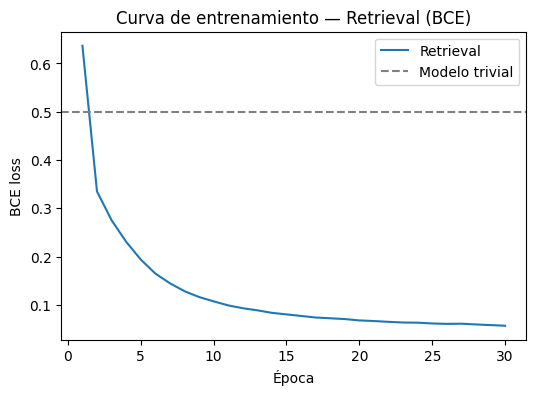

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.plot(range(1, N_EPOCHS_RETRIEVAL + 1), retrieval_losses, label='Retrieval')
plt.axhline(trivial_bce, color='gray', linestyle='--', label='Modelo trivial')
plt.legend()
plt.title('Curva de entrenamiento — Retrieval (BCE)')
plt.xlabel('Época')
plt.ylabel('BCE loss')
plt.show()

## 4. Candidatos del retrieval

Para todos los usuarios, de una sola vez, se puntúa el catálogo con el retrieval, se enmascara lo que ya vieron en train y se guardan los 500 mejores ítems. El candidato número N de cada usuario es la columna N de esa matriz, así que después se pueden probar distintos tamaños de lista de candidatos sin volver a calcular nada.

También se calcula el **recall de candidatos**: qué fracción de los ítems relevantes del test entra en los N candidatos. Es el techo de lo que cualquier ranker posterior puede lograr.

In [9]:
MAX_CANDIDATES = 500
TOP_K = 10

# Máscara (usuario, ítem) de lo visto en train: nunca se recomienda
seen_mask_np = np.zeros((n_users, n_items), dtype=bool)
seen_mask_np[train_df['user_idx'].values, train_df['item_idx'].values] = True

retrieval_model.eval()
with torch.no_grad():
    all_users_t = torch.arange(n_users, dtype=torch.long, device=device)
    all_items_t = torch.arange(n_items, dtype=torch.long, device=device)
    user_embeds = retrieval_model.forward_user(all_users_t)      # (n_users, d)
    item_embeds = retrieval_model.forward_item(all_items_t)      # (n_items, d)
    retr_scores = user_embeds @ item_embeds.T                    # (n_users, n_items)
    retr_scores = retr_scores.masked_fill(torch.from_numpy(seen_mask_np).to(device), -float('inf'))
    retrieval_topk = torch.topk(retr_scores, MAX_CANDIDATES, dim=1).indices.cpu().numpy()  # ordenados de mayor a menor

# Ítems relevantes de cada usuario en test
test_relevant_by_user = (
    test_df[test_df['rating'] >= RATING_THRESHOLD]
    .groupby('user_idx')['item_idx']
    .apply(set)
    .to_dict()
)
eval_users = list(test_relevant_by_user.keys())
print(f'Usuarios evaluables (con al menos un ítem relevante en test): {len(eval_users)}')

for n in (10, 50, 100, 200, 500):
    cand_recall = np.mean([
        len(set(retrieval_topk[u, :n]) & test_relevant_by_user[u]) / len(test_relevant_by_user[u])
        for u in eval_users
    ])
    print(f'Recall de candidatos @ {n:>3}: {cand_recall:.4f}')

Usuarios evaluables (con al menos un ítem relevante en test): 601
Recall de candidatos @  10: 0.1275
Recall de candidatos @  50: 0.3285
Recall de candidatos @ 100: 0.4441
Recall de candidatos @ 200: 0.5700
Recall de candidatos @ 500: 0.7290


## 5. Etapa B — Ranker

**Características que usa (todas calculadas sólo con train):**
- Embeddings propios de usuario e ítem (distintos de los del retrieval) y su producto elemento a elemento. Una MLP sola aprende mal los productos punto, por eso se los damos ya calculados.
- Géneros del ítem (multi-hot), perfil de géneros del usuario (proporción de géneros entre sus positivos de train) y el producto elemento a elemento de ambos.
- Popularidad del ítem (log del conteo de positivos en train, normalizado).

Nota: el perfil de géneros y la popularidad incluyen, durante el entrenamiento, al propio positivo que se intenta predecir. Con ~80 positivos por usuario el efecto es pequeño, pero es una fuga leve que conviene tener presente al discutir resultados.

**Dos variantes de negativos**, para que los datos decidan cuál conviene:
- *uniforme*: 4 negativos al azar por positivo.
- *mixto*: 2 al azar + 2 tomados de los candidatos del retrieval que el usuario no vio en train. Estos "negativos difíciles" se parecen a lo que el ranker va a ver en producción (candidatos plausibles), pero algunos pueden ser en realidad positivos todavía no observados.

In [10]:
# Géneros de cada ítem (multi-hot)
movies = pd.read_csv(f'{DATA_DIR}/ml-latest-small/movies.csv')
movie_genres = dict(zip(movies['movieId'], movies['genres'].str.split('|')))
all_genres = sorted({g for gl in movie_genres.values() for g in gl if g != '(no genres listed)'})
genre2col = {g: c for c, g in enumerate(all_genres)}
n_genres = len(all_genres)

item_genre_np = np.zeros((n_items, n_genres), dtype=np.float32)
for movie_id, idx in item2idx.items():
    for g in movie_genres.get(movie_id, []):
        if g in genre2col:
            item_genre_np[idx, genre2col[g]] = 1.0

# Perfil de géneros del usuario: distribución de géneros entre sus positivos de train
user_pos_np = np.zeros((n_users, n_items), dtype=np.float32)
user_pos_np[train_positive['user_idx'].values, train_positive['item_idx'].values] = 1.0
user_genre_np = user_pos_np @ item_genre_np
user_genre_np = user_genre_np / np.maximum(user_genre_np.sum(axis=1, keepdims=True), 1.0)

# Popularidad del ítem: conteo de positivos en train
item_popularity = np.zeros(n_items)
pop_counts = train_positive['item_idx'].value_counts()
item_popularity[pop_counts.index.values] = pop_counts.values
item_logpop_np = np.log1p(item_popularity)
item_logpop_np = (item_logpop_np / item_logpop_np.max()).astype(np.float32)

print(f'{n_genres} géneros | ítems sin ningún género asignado: {int((item_genre_np.sum(axis=1) == 0).sum())}')

19 géneros | ítems sin ningún género asignado: 34


In [11]:
import torch.nn as nn
import torch.optim as optim

class Ranker(nn.Module):
    def __init__(self, n_users, n_items, user_genre, item_genre, item_logpop,
                 embed_dim=32, hidden=(128, 64), dropout=0.2):
        super().__init__()
        self.user_emb = nn.Embedding(n_users, embed_dim)
        self.item_emb = nn.Embedding(n_items, embed_dim)
        nn.init.normal_(self.user_emb.weight, mean=0.0, std=0.1)
        nn.init.normal_(self.item_emb.weight, mean=0.0, std=0.1)

        # Características fijas (no se entrenan); register_buffer las mueve junto con el modelo a la GPU
        self.register_buffer('user_genre', torch.tensor(user_genre))
        self.register_buffer('item_genre', torch.tensor(item_genre))
        self.register_buffer('item_logpop', torch.tensor(item_logpop))

        g = item_genre.shape[1]
        in_dim = 3 * embed_dim + 3 * g + 1
        layers = []
        for h in hidden:
            layers += [nn.Linear(in_dim, h), nn.ReLU(), nn.Dropout(dropout)]
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))
        self.mlp = nn.Sequential(*layers)

    def forward(self, user_idx, item_idx):
        ue, ie = self.user_emb(user_idx), self.item_emb(item_idx)
        ug, ig = self.user_genre[user_idx], self.item_genre[item_idx]
        lp = self.item_logpop[item_idx].unsqueeze(-1)
        x = torch.cat([ue, ie, ue * ie, ug, ig, ug * ig, lp], dim=-1)
        return self.mlp(x).squeeze(-1)   # logit (sin sigmoide: la pérdida la aplica internamente)

In [12]:
HARD_POOL = 100  # los negativos difíciles se eligen entre los 100 mejores candidatos del retrieval

def sample_ranker_negatives(pos_users, n_uniform, n_hard):
    # Devuelve una matriz (n_positivos, n_uniform + n_hard) con ítems negativos para cada positivo.
    P = len(pos_users)
    parts = []
    if n_uniform > 0:
        neg = np.random.randint(0, n_items, size=(P, n_uniform))
        bad = seen_mask_np[pos_users[:, None], neg]
        while bad.any():  # re-sampleamos sólo los que cayeron en algo que el usuario vio en train
            neg[bad] = np.random.randint(0, n_items, size=int(bad.sum()))
            bad = seen_mask_np[pos_users[:, None], neg]
        parts.append(neg)
    if n_hard > 0:
        cols = np.random.randint(0, HARD_POOL, size=(P, n_hard))
        parts.append(retrieval_topk[pos_users[:, None], cols])   # ya excluyen lo visto en train
    return np.concatenate(parts, axis=1)


def train_ranker(n_uniform, n_hard, n_epochs=8, lr=2e-3, batch_size=1024, seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)

    model = Ranker(n_users, n_items, user_genre_np, item_genre_np, item_logpop_np).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    criterion = nn.BCEWithLogitsLoss()

    pos_users = train_positive['user_idx'].values
    pos_items = train_positive['item_idx'].values
    k = n_uniform + n_hard
    losses = []

    for epoch in range(1, n_epochs + 1):
        neg = sample_ranker_negatives(pos_users, n_uniform, n_hard)          # (P, k)
        u_all = np.concatenate([pos_users, np.repeat(pos_users, k)])
        i_all = np.concatenate([pos_items, neg.reshape(-1)])
        y_all = np.concatenate([np.ones(len(pos_users)), np.zeros(len(pos_users) * k)]).astype(np.float32)

        u_t = torch.tensor(u_all, dtype=torch.long, device=device)
        i_t = torch.tensor(i_all, dtype=torch.long, device=device)
        y_t = torch.tensor(y_all, dtype=torch.float32, device=device)
        perm = torch.randperm(len(y_t), device=device)

        model.train()
        total = 0.0
        for s in range(0, len(perm), batch_size):
            idx = perm[s:s + batch_size]
            optimizer.zero_grad()
            loss = criterion(model(u_t[idx], i_t[idx]), y_t[idx])
            loss.backward()
            optimizer.step()
            total += loss.item() * len(idx)

        losses.append(total / len(perm))
        print(f'Epoch {epoch}/{n_epochs} - Ranker BCE: {losses[-1]:.4f}')

    model.eval()
    return model, losses

In [13]:
p_pos = 1 / (1 + 4)
print(f'BCE de referencia (modelo trivial, 4 negativos por positivo): {-(p_pos*np.log(p_pos) + (1-p_pos)*np.log(1-p_pos)):.4f}')

rankers = {}
for variant, (n_uni, n_hard) in {'uniforme': (4, 0), 'mixto': (2, 2)}.items():
    print(f'\n=== Ranker [{variant}]: {n_uni} negativos uniformes + {n_hard} del retrieval por positivo ===')
    rankers[variant], _ = train_ranker(n_uni, n_hard)

print('\nNota: la BCE de las dos variantes no es comparable entre sí (los negativos son distintos).')

BCE de referencia (modelo trivial, 4 negativos por positivo): 0.5004

=== Ranker [uniforme]: 4 negativos uniformes + 0 del retrieval por positivo ===
Epoch 1/8 - Ranker BCE: 0.3411
Epoch 2/8 - Ranker BCE: 0.2647
Epoch 3/8 - Ranker BCE: 0.2449
Epoch 4/8 - Ranker BCE: 0.2030
Epoch 5/8 - Ranker BCE: 0.1525
Epoch 6/8 - Ranker BCE: 0.1219
Epoch 7/8 - Ranker BCE: 0.1022
Epoch 8/8 - Ranker BCE: 0.0926

=== Ranker [mixto]: 2 negativos uniformes + 2 del retrieval por positivo ===
Epoch 1/8 - Ranker BCE: 0.4769
Epoch 2/8 - Ranker BCE: 0.4247
Epoch 3/8 - Ranker BCE: 0.3707
Epoch 4/8 - Ranker BCE: 0.2965
Epoch 5/8 - Ranker BCE: 0.2400
Epoch 6/8 - Ranker BCE: 0.2067
Epoch 7/8 - Ranker BCE: 0.1845
Epoch 8/8 - Ranker BCE: 0.1649

Nota: la BCE de las dos variantes no es comparable entre sí (los negativos son distintos).


## 6. Evaluación

Se comparan, con el mismo protocolo (top-10 sobre el catálogo no visto en train, relevantes = rating ≥ 3.5 en test):

- **Popularidad:** los 10 ítems más populares no vistos.
- **Retrieval solo:** los 10 primeros candidatos, sin ranker.
- **Ranker, catálogo completo (1 etapa):** el ranker puntúa los ~9700 ítems de cada usuario. Es el "techo" de calidad de esa familia de modelos, y el más caro.
- **Two-Stage con N candidatos:** el retrieval se queda con N candidatos y el ranker sólo puntúa esos N. Es la arquitectura en sí.

Métricas: precision@10, recall@10, NDCG@10 (premia que los relevantes estén más arriba en la lista), **cobertura** (fracción del catálogo que aparece recomendada a al menos un usuario), **popularidad media** de lo recomendado (cuanto más alta, más sesgo hacia lo popular) y milisegundos por usuario.

In [14]:
import time

all_items_np = np.arange(n_items)
discount = 1.0 / np.log2(np.arange(2, TOP_K + 2))

def score_with_ranker(model, user_idx, item_idx_array):
    with torch.no_grad():
        items_t = torch.as_tensor(item_idx_array, dtype=torch.long, device=device)
        users_t = torch.full_like(items_t, int(user_idx))
        return model(users_t, items_t).cpu().numpy().copy()

# ---- Estrategias: cada una recibe un usuario y devuelve sus 10 ítems recomendados ----
def rec_popularity(u):
    scores = item_popularity.astype(np.float64)
    scores[seen_mask_np[u]] = -np.inf
    return np.argsort(-scores)[:TOP_K]

def rec_retrieval_only(u):
    return retrieval_topk[u, :TOP_K]

def make_one_stage(model):
    def rec(u):
        scores = score_with_ranker(model, u, all_items_np)
        scores[seen_mask_np[u]] = -np.inf
        return np.argsort(-scores)[:TOP_K]
    return rec

def make_two_stage(model, n_candidates):
    def rec(u):
        cands = retrieval_topk[u, :n_candidates]
        scores = score_with_ranker(model, u, cands)
        return cands[np.argsort(-scores)[:TOP_K]]
    return rec

def evaluate(name, rec_fn):
    if device.type == 'cuda':
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    lists = [rec_fn(u) for u in eval_users]
    if device.type == 'cuda':
        torch.cuda.synchronize()
    ms_per_user = (time.perf_counter() - t0) / len(eval_users) * 1000

    precs, recs, ndcgs = [], [], []
    for u, top in zip(eval_users, lists):
        relevant = test_relevant_by_user[u]
        rel = np.array([1.0 if i in relevant else 0.0 for i in top])
        precs.append(rel.sum() / TOP_K)
        recs.append(rel.sum() / len(relevant))
        ideal = discount[:min(len(relevant), TOP_K)].sum()
        ndcgs.append((rel * discount).sum() / ideal)

    all_recs = np.concatenate(lists)
    return {
        'modelo': name,
        'precision_at_10': np.mean(precs),
        'recall_at_10': np.mean(recs),
        'ndcg_at_10': np.mean(ndcgs),
        'cobertura_catalogo': len(set(all_recs.tolist())) / n_items,
        'popularidad_media_recs': float(item_popularity[all_recs].mean()),
        'ms_por_usuario': ms_per_user,
    }

In [15]:
results_rows = [
    evaluate('Popularidad (baseline)', rec_popularity),
    evaluate('Retrieval (two-tower) solo', rec_retrieval_only),
]
for variant, model in rankers.items():
    results_rows.append(evaluate(f'Ranker[{variant}] catálogo completo (1 etapa)', make_one_stage(model)))
    for n in (50, 200):
        results_rows.append(evaluate(f'Two-Stage[{variant}] N={n}', make_two_stage(model, n)))

results_df = pd.DataFrame(results_rows)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
results_df.round(4)

,modelo,precision_at_10,recall_at_10,ndcg_at_10,cobertura_catalogo,popularidad_media_recs,ms_por_usuario
0,Popularidad (baseline),0.1401,0.0939,0.1738,0.0061,163.4950,0.2803
1,Retrieval (two-tower) solo,0.1478,0.1275,0.1907,0.0835,85.3145,0.0004
2,Ranker[uniforme] catálogo completo (1 etapa),0.1549,0.1278,0.1973,0.0906,110.8221,1.3986
3,Two-Stage[uniforme] N=50,0.1800,0.1437,0.2295,0.0639,113.2907,0.7783
4,Two-Stage[uniforme] N=200,0.1737,0.1350,0.2168,0.0629,119.7709,0.7073
5,Ranker[mixto] catálogo completo (1 etapa),0.0186,0.0120,0.0198,0.2090,16.2942,1.2473
6,Two-Stage[mixto] N=50,0.1661,0.1422,0.2065,0.0758,84.5607,0.7259
7,Two-Stage[mixto] N=200,0.0656,0.0649,0.0790,0.1532,43.1692,0.7537


### Cómo leer la tabla

1. **¿El retrieval aporta algo sobre popularidad?** Comparar *Retrieval solo* contra *Popularidad* en precision/recall/NDCG, y mirar también cobertura: un modelo personalizado debería recomendar una porción mayor del catálogo.
2. **¿El ranker mejora al retrieval?** Comparar *Two-Stage* contra *Retrieval solo*. Si empeora, el ranker no está aportando.
3. **¿Vale la pena la arquitectura de dos etapas?** Comparar *Two-Stage* contra *Ranker catálogo completo*: si la calidad es parecida y el tiempo por usuario es menor, la arquitectura cumple su función. Con ~9700 ítems la diferencia de tiempo es chica; la ventaja crece con el tamaño del catálogo (en sistemas reales, millones de ítems, puntuar todo con el ranker es inviable).
4. **Efecto de N:** más candidatos suben el techo (recall de candidatos) pero cuestan más tiempo.
5. **Sesgo:** *popularidad media* y *cobertura* son las primeras mediciones de sesgo del proyecto; van a servir de referencia para la Etapa 4.

**Advertencias metodológicas:** (a) es una sola corrida con una sola semilla; diferencias de uno o dos puntos en la tercera decimal no son concluyentes. (b) Elegir "la mejor variante" mirando estos mismos números de test infla el resultado; para la tesis conviene fijar la configuración con un conjunto de validación separado, o reportar todas las variantes sin elegir. (c) El test set tiene ítems que nunca aparecen en train (cold-start), que ningún modelo de esta etapa puede recomendar bien.

## 7. Guardar resultados en la tabla comparativa

Se agrega una columna `protocolo` para que nadie compare como equivalentes los números de la evaluación pointwise de las Etapas 1 y 2 con los de esta evaluación, que es más exigente. Se reemplazan las filas de corridas anteriores de esta etapa.

In [16]:
import warnings
from datetime import datetime

results_path = f'{PROJECT_DIR}/results/comparativa_modelos.csv'
PROTOCOLO_FULL = 'full-ranking (top-10 sobre catálogo no visto en train)'
PROTOCOLO_POINTWISE = 'pointwise (rating predicho vs. umbral 3.5)'

new_df = results_df.copy()
new_df['protocolo'] = PROTOCOLO_FULL
new_df['fecha'] = datetime.now().isoformat(timespec='seconds')

with warnings.catch_warnings():
    warnings.simplefilter('ignore', category=FutureWarning)
    if os.path.exists(results_path):
        previous = pd.read_csv(results_path)
        if 'protocolo' not in previous.columns:
            previous['protocolo'] = None
        # Etapas 1 y 2: se etiquetan como pointwise si todavía no tenían protocolo
        old_stages = previous['modelo'].isin(['SVD (baseline)', 'NCF (NeuMF)']) & previous['protocolo'].isna()
        previous.loc[old_stages, 'protocolo'] = PROTOCOLO_POINTWISE
        # Se descartan corridas anteriores de esta etapa para no duplicar filas
        drop = previous['modelo'].str.startswith(('Two-Stage', 'Retrieval', 'Ranker', 'Popularidad'))
        results = pd.concat([previous[~drop], new_df], ignore_index=True)
    else:
        results = new_df

results.to_csv(results_path, index=False)
print('Resultados guardados en', results_path)
results

Resultados guardados en /content/drive/MyDrive/tesis-recsys/results/comparativa_modelos.csv


,modelo,rmse,mae,precision_at_10,recall_at_10,fecha,protocolo,ndcg_at_10,cobertura_catalogo,popularidad_media_recs,ms_por_usuario
0,SVD (baseline),0.880746,0.676573,0.744629,0.508616,2026-09-12T20:00:25,pointwise (rating predicho vs. umbral 3.5),NaN,NaN,NaN,NaN
1,NCF (NeuMF),0.964550,0.738843,0.741954,0.522332,2026-09-27T01:14:26,pointwise (rating predicho vs. umbral 3.5),NaN,NaN,NaN,NaN
2,Popularidad (baseline),NaN,NaN,0.140100,0.093947,2026-11-09T20:26:06,full-ranking (top-10 sobre catálogo no visto e...,0.173799,0.006067,163.495008,0.280346
3,Retrieval (two-tower) solo,NaN,NaN,0.147754,0.127539,2026-11-09T20:26:06,full-ranking (top-10 sobre catálogo no visto e...,0.190736,0.083505,85.314476,0.000367
4,Ranker[uniforme] catálogo completo (1 etapa),NaN,NaN,0.154908,0.127845,2026-11-09T20:26:06,full-ranking (top-10 sobre catálogo no visto e...,0.197289,0.090601,110.822130,1.398557
5,Two-Stage[uniforme] N=50,NaN,NaN,0.180033,0.143718,2026-11-09T20:26:06,full-ranking (top-10 sobre catálogo no visto e...,0.229479,0.063863,113.290682,0.778326
6,Two-Stage[uniforme] N=200,NaN,NaN,0.173710,0.135011,2026-11-09T20:26:06,full-ranking (top-10 sobre catálogo no visto e...,0.216809,0.062937,119.770882,0.707322
7,Ranker[mixto] catálogo completo (1 etapa),NaN,NaN,0.018636,0.011967,2026-11-09T20:26:06,full-ranking (top-10 sobre catálogo no visto e...,0.019814,0.208968,16.294176,1.247257
8,Two-Stage[mixto] N=50,NaN,NaN,0.166057,0.142212,2026-11-09T20:26:06,full-ranking (top-10 sobre catálogo no visto e...,0.206462,0.075792,84.560732,0.725893
9,Two-Stage[mixto] N=200,NaN,NaN,0.065557,0.064936,2026-11-09T20:26:06,full-ranking (top-10 sobre catálogo no visto e...,0.079047,0.153229,43.169218,0.753729


## Próximos pasos

- Anotar en el research log: qué cambió respecto de la primera versión (ranker pasó de regresión de rating a feedback implícito con características de contenido; se agregó baseline de popularidad, NDCG, cobertura y popularidad media) y por qué.
- Si el retrieval no supera claramente a popularidad en la tabla, el cuello de botella está en esa etapa: el recall de candidatos de la sección 4 indica cuánto margen hay.
- Etapa 4: reemplazar la torre de ítems del retrieval por una que incorpore embeddings semánticos de modelos de lenguaje, y comparar contra esta misma tabla. Es útil que ya existan acá la cobertura y la popularidad media como medidas de sesgo.